# Chapter 8 · Antithetic variates, moment matching and control variates: interactive demos

Companion to Chapter 8 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/08-antithetic-control.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

Throughout, the test case is $S=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$ (call price 7.36429), and
$S_T = S\exp(\nu T + \sigma\sqrt T Z)$ with $\nu = r-y-\sigma^2/2$.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import time
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d.bs import TEST_CASE, call
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style
from mfe230d.variance import (antithetic, antithetic_correlation, control_variate, crn_difference,
                              moment_match, moment_matched, plain, regression_control_variates,
                              strike_to_z, terminal_price, DEVIOUS, sqrt_option_samples,
                              sqrt_control_mean, sqrt_call)

use_style()
GREEN = "#1BAF7A"
P = TEST_CASE
S, K, T, r, y, SIG = (P[k] for k in ("S", "K", "T", "r", "y", "sigma"))
DISC = np.exp(-r * T)

## 1. Antithetic variates: the even part is all that is left

Pairing each draw $Z$ with $-Z$ integrates the odd part $f_o(z)=\frac12(f(z)-f(-z))$ of the payoff exactly;
only the even part $f_e(z)=\frac12(f(z)+f(-z))$ is sampled (Proposition 8.2). The left panel splits a payoff
into the two parts; the right panel shows the antithetic correlation $\rho$ against the strike. Antithetic
sampling beats plain sampling with the same number of payoff evaluations exactly when $\rho<0$.

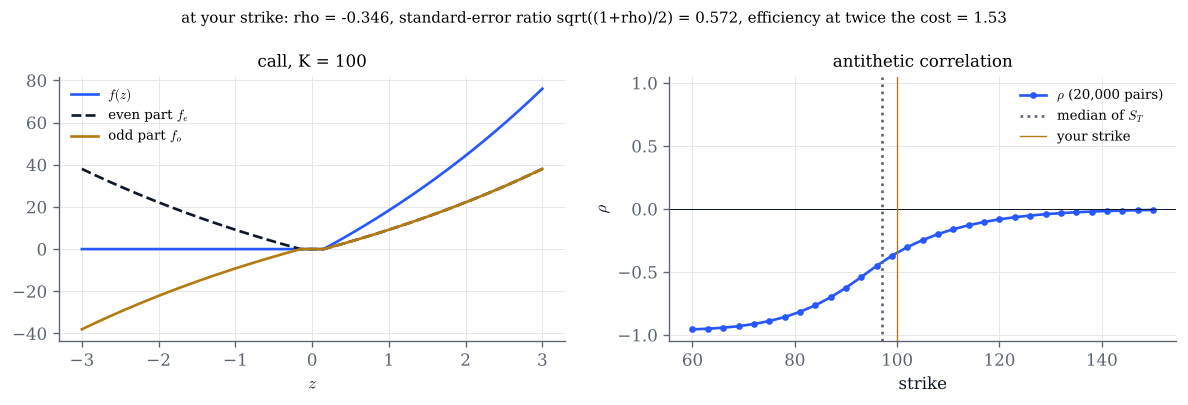

In [2]:
PAYOFFS = {
    "call": lambda ST, k: np.maximum(ST - k, 0.0),
    "put": lambda ST, k: np.maximum(k - ST, 0.0),
    "digital call": lambda ST, k: (ST > k).astype(float),
    "straddle": lambda ST, k: np.abs(ST - k),
    "butterfly (k-10, k, k+10)": lambda ST, k: (np.maximum(ST - k + 10, 0) - 2 * np.maximum(ST - k, 0)
                                               + np.maximum(ST - k - 10, 0)),
}

def antithetic_demo(payoff="call", strike=100.0, sigma=0.20, T_=1.0):
    f = lambda u, k=strike: DISC * PAYOFFS[payoff](terminal_price(u, S, T_, r, y, sigma), k)
    u = np.linspace(-3, 3, 601)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(u, f(u), color=COBALT, label="$f(z)$")
    ax.plot(u, 0.5 * (f(u) + f(-u)), color=INK, ls="--", label="even part $f_e$")
    ax.plot(u, 0.5 * (f(u) - f(-u)), color=GOLD, label="odd part $f_o$")
    ax.set(xlabel="$z$", title=f"{payoff}, K = {strike:g}")
    ax.legend(fontsize=8)
    z = np.random.default_rng(0).standard_normal(20_000)
    ks = np.linspace(60, 150, 31)
    rho = [antithetic(lambda v, k=k: DISC * PAYOFFS[payoff](terminal_price(v, S, T_, r, y, sigma), k), z)["rho"]
           for k in ks]
    bx.plot(ks, rho, color=COBALT, marker="o", ms=3, label="$\\rho$ (20,000 pairs)")
    bx.axhline(0, color=INK, lw=0.6)
    bx.axvline(S * np.exp((r - y - sigma**2 / 2) * T_), color=GREY, ls=":", label="median of $S_T$")
    bx.axvline(strike, color=GOLD, lw=0.8, label="your strike")
    bx.set(xlabel="strike", ylabel="$\\rho$", ylim=(-1.05, 1.05), title="antithetic correlation")
    bx.legend(fontsize=8)
    a = antithetic(f, z)
    fig.suptitle(f"at your strike: rho = {a['rho']:+.3f}, standard-error ratio sqrt((1+rho)/2) = "
                 f"{np.sqrt(max(0, (1 + a['rho']) / 2)):.3f}, efficiency at twice the cost = {1 / max(1e-12, 1 + a['rho']):.2f}",
                 fontsize=9)
    fig.tight_layout()
    plt.show()

antithetic_demo()

In [3]:
# Explore: which payoffs, and which strikes, does pairing help? Try the straddle and the butterfly near the median.
interact(antithetic_demo,
         payoff=Dropdown(options=list(PAYOFFS), value="call", description="payoff"),
         strike=FloatSlider(value=100, min=60, max=150, step=1, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.20, min=0.05, max=0.80, step=0.05, continuous_update=False, description="σ"),
         T_=FloatSlider(value=1.0, min=0.1, max=5.0, step=0.1, continuous_update=False, description="T"));

## 2. Moment matching: dependent draws, batches and a bias of order $1/n$

Log moment matching replaces $Z_i$ by $Z'_i=(Z_i-\bar Z_n)/\hat s_n$. The adjusted draws are dependent, so the
naive CLT standard error is wrong, and the estimator has a bias of order $1/n$ (Proposition 8.7). The left panel
shows $n$ times the bias of the matched estimate of the call, from many replications, next to the predicted
constant $1.75$; the right panel compares the naive standard error with the batch standard error and with the
true spread of the estimate.

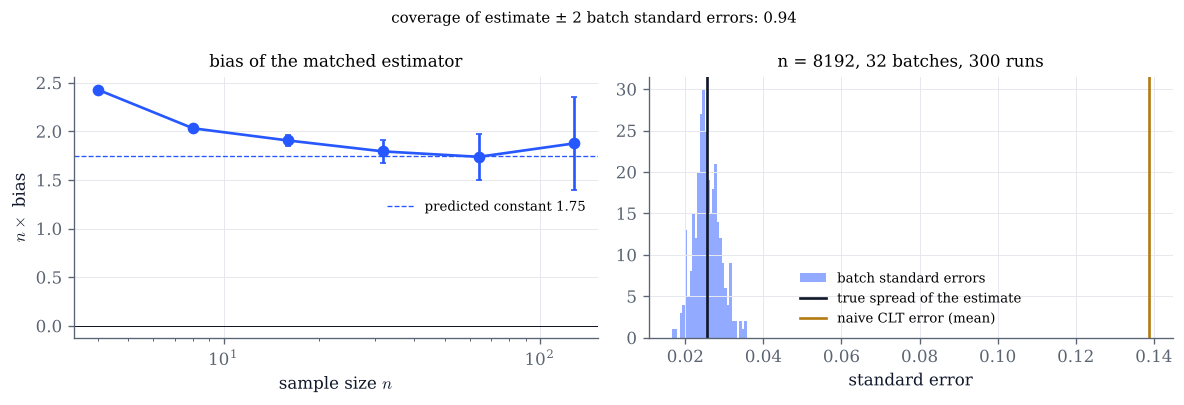

In [4]:
def mm_demo(strike=100.0, n_batches=32, n_total=8192, seed=1):
    price = float(call(S, strike, T, r, y, SIG))
    f = lambda u: DISC * np.maximum(terminal_price(u, S, T, r, y, SIG) - strike, 0.0)
    rng = np.random.default_rng(seed)
    ns = np.array([4, 8, 16, 32, 64, 128])
    nb, eb = [], []
    for n in ns:
        R = 1_600_000 // n
        est = f(moment_match(rng.standard_normal((R, n)), "log")).mean(1)
        nb.append(n * (est.mean() - price)); eb.append(2 * n * est.std() / np.sqrt(R))
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.errorbar(ns, nb, yerr=eb, color=COBALT, marker="o", capsize=2)
    ax.axhline(0, color=INK, lw=0.6)
    if strike == 100.0:
        ax.axhline(1.75, color=COBALT, ls="--", lw=0.8, label="predicted constant 1.75")
        ax.legend(fontsize=8)
    ax.set(xscale="log", xlabel="sample size $n$", ylabel="$n\\times$ bias", title="bias of the matched estimator")
    reps = 300
    runs = [moment_matched(f, rng.standard_normal(n_total), n_batches, "log") for _ in range(reps)]
    means = np.array([o["mean"] for o in runs])
    bx.hist([o["se"] for o in runs], bins=30, color=COBALT, alpha=0.5, label="batch standard errors")
    bx.axvline(means.std(), color=INK, lw=1.6, label="true spread of the estimate")
    bx.axvline(np.mean([o["naive_se"] for o in runs]), color=GOLD, lw=1.6, label="naive CLT error (mean)")
    bx.set(xlabel="standard error", title=f"n = {n_total}, {n_batches} batches, {reps} runs")
    bx.legend(fontsize=8)
    cover = np.mean(np.abs(means - price) <= 2 * np.array([o["se"] for o in runs]))
    fig.suptitle(f"coverage of estimate ± 2 batch standard errors: {cover:.2f}", fontsize=9)
    fig.tight_layout()
    plt.show()

mm_demo()

In [5]:
# Explore: with many small batches the bias catches up with the standard error and coverage collapses.
interact(mm_demo,
         strike=FloatSlider(value=100, min=70, max=140, step=5, continuous_update=False, description="K"),
         n_batches=Dropdown(options=[4, 8, 16, 32, 64, 128, 256, 512], value=32, description="batches"),
         n_total=Dropdown(options=[1024, 4096, 8192, 16384], value=8192, description="n"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 3. Control variates: the coefficient matters

For a control $X$ with known mean, $\mathrm{Var}(Y-\beta X)$ is a parabola in $\beta$, minimal at
$\beta^*=\mathrm{Cov}(X,Y)/\mathrm{Var}X$ with value $(1-\rho^2)\mathrm{Var}Y$ (Theorem 8.12). Here the target
is a call at strike $K$ and the control is a call at strike $K_c$ (both have closed forms). With $K=K_c$ the
control is perfect.

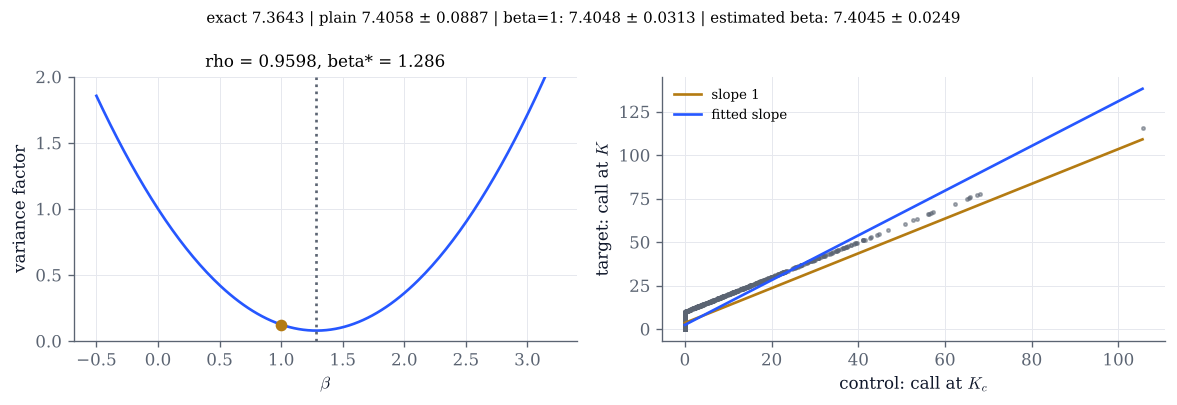

In [6]:
def cv_demo(strike=100.0, control_strike=110.0, beta=1.0, n=20_000, seed=2):
    z = np.random.default_rng(seed).standard_normal(n)
    ST = terminal_price(z, S, T, r, y, SIG)
    Y = DISC * np.maximum(ST - strike, 0.0)
    X = DISC * np.maximum(ST - control_strike, 0.0)
    mux = float(call(S, control_strike, T, r, y, SIG))
    cov = np.cov(X, Y); bstar = cov[0, 1] / cov[0, 0]; rho = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    bs = np.linspace(-0.5, max(2.5 * bstar, 1.5), 200)
    fac = (cov[1, 1] - 2 * bs * cov[0, 1] + bs**2 * cov[0, 0]) / cov[1, 1]
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(bs, fac, color=COBALT)
    ax.axvline(bstar, color=GREY, ls=":")
    ax.plot(beta, (cov[1, 1] - 2 * beta * cov[0, 1] + beta**2 * cov[0, 0]) / cov[1, 1], "o", color=GOLD)
    ax.set(xlabel="$\\beta$", ylabel="variance factor", title=f"rho = {rho:.4f}, beta* = {bstar:.3f}",
           ylim=(0, max(2, fac.min() + 0.1)))
    idx = np.random.default_rng(0).choice(n, 1500, replace=False)
    bx.plot(X[idx], Y[idx], "o", ms=2, color=GREY, alpha=0.5)
    xs = np.linspace(0, X.max(), 50)
    bx.plot(xs, Y.mean() + beta * (xs - X.mean()), color=GOLD, label=f"slope {beta:g}")
    bx.plot(xs, Y.mean() + bstar * (xs - X.mean()), color=COBALT, label="fitted slope")
    bx.set(xlabel="control: call at $K_c$", ylabel="target: call at $K$"); bx.legend(fontsize=8)
    out_b, out_s, out_p = control_variate(Y, X, mux, beta), control_variate(Y, X, mux), plain(Y)
    exact = float(call(S, strike, T, r, y, SIG))
    fig.suptitle(f"exact {exact:.4f} | plain {out_p['mean']:.4f} ± {out_p['se']:.4f} | "
                 f"beta={beta:g}: {out_b['mean']:.4f} ± {out_b['se']:.4f} | estimated beta: "
                 f"{out_s['mean']:.4f} ± {out_s['se']:.4f}", fontsize=9)
    fig.tight_layout()
    plt.show()

cv_demo()

In [7]:
# Explore: move the control's strike away from the target's and watch rho and beta*.
interact(cv_demo,
         strike=FloatSlider(value=100, min=70, max=140, step=5, continuous_update=False, description="K"),
         control_strike=FloatSlider(value=110, min=50, max=160, step=5, continuous_update=False, description="K_c"),
         beta=FloatSlider(value=1.0, min=-0.5, max=3.0, step=0.05, continuous_update=False, description="β"),
         n=IntSlider(value=20_000, min=1_000, max=200_000, step=1_000, continuous_update=False, description="n"),
         seed=IntSlider(value=2, min=0, max=50, continuous_update=False, description="seed"));

## 4. Common random numbers for a price difference

To estimate the change in the call price when the volatility moves from $\sigma$ to $\sigma+h$, use the same
normals for both prices (Proposition 8.11). Both payoffs increase with $z$, so their correlation is close to one,
and the standard error of the difference quotient stays bounded as $h\to0$; with independent draws it grows like
$1/h$.

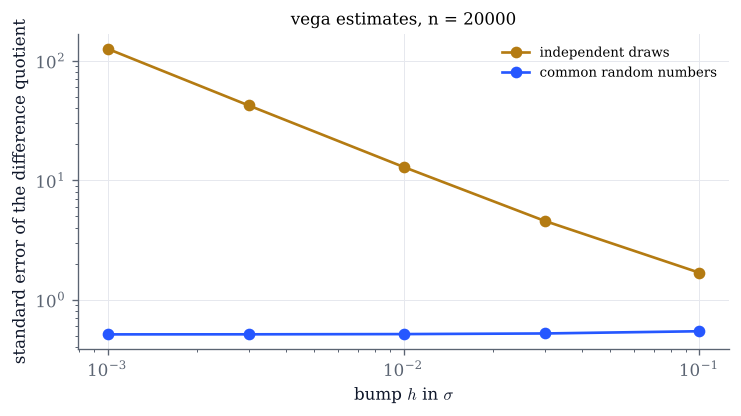

In [8]:
def crn_demo(n=20_000, seed=3):
    rng = np.random.default_rng(seed)
    z, z2 = rng.standard_normal(n), rng.standard_normal(n)
    hs = np.array([0.1, 0.03, 0.01, 0.003, 0.001])
    se_c, se_i = [], []
    for h in hs:
        f0 = lambda u: DISC * np.maximum(terminal_price(u, S, T, r, y, SIG) - K, 0.0) / h
        f1 = lambda u: DISC * np.maximum(terminal_price(u, S, T, r, y, SIG + h) - K, 0.0) / h
        se_c.append(crn_difference(f1, f0, z)["se"]); se_i.append(crn_difference(f1, f0, z, z2)["se"])
    fig, ax = plt.subplots(figsize=(7, 3.4))
    ax.loglog(hs, se_i, color=GOLD, marker="o", label="independent draws")
    ax.loglog(hs, se_c, color=COBALT, marker="o", label="common random numbers")
    ax.set(xlabel="bump $h$ in $\\sigma$", ylabel="standard error of the difference quotient",
           title=f"vega estimates, n = {n}")
    ax.legend(fontsize=8)
    plt.show()

crn_demo()

In [9]:
interact(crn_demo,
         n=IntSlider(value=20_000, min=1_000, max=200_000, step=1_000, continuous_update=False, description="n"),
         seed=IntSlider(value=3, min=0, max=50, continuous_update=False, description="seed"));

## 5. The laboratory, with measured times

Every method of the chapter on the same draws, for the call at strike $K$. Efficiency here uses **measured**
execution times, $\mathcal E = \sigma_1^2\tau_1/(\sigma_2^2\tau_2)$, instead of the conservative cost factor
$c=2$ of Table 8.1. Timings depend on your machine and are noisy for small $n$: rerun a few times.

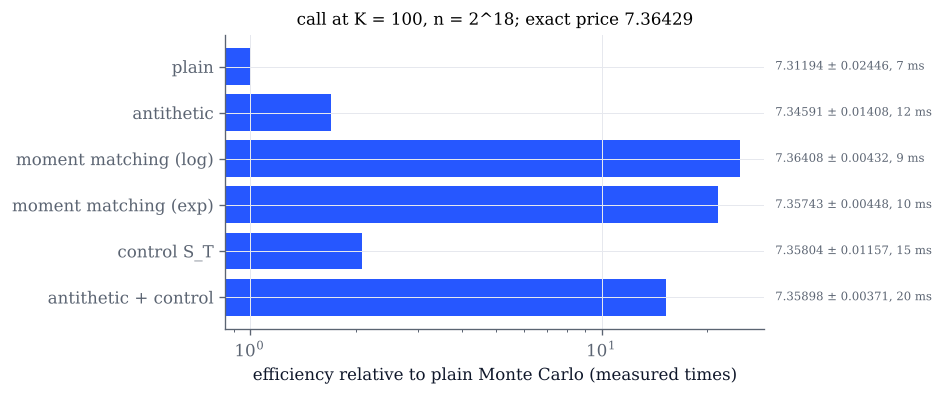

In [10]:
def lab_demo(strike=100.0, log2n=18, seed=1):
    n = 2**log2n
    s = SIG * np.sqrt(T)
    rng = np.random.default_rng(seed)
    f = lambda u: DISC * np.maximum(terminal_price(u, S, T, r, y, SIG) - strike, 0.0)
    g = lambda u: DISC * terminal_price(u, S, T, r, y, SIG)
    mu_g = S * np.exp(-y * T)
    methods = {
        "plain": lambda z: plain(f(z)),
        "antithetic": lambda z: antithetic(f, z),
        "moment matching (log)": lambda z: moment_matched(f, z, 256, "log"),
        "moment matching (exp)": lambda z: moment_matched(f, z, 256, "exp", s),
        "control S_T": lambda z: control_variate(f(z), g(z), mu_g),
        "antithetic + control": lambda z: control_variate(0.5 * (f(z) + f(-z)), 0.5 * (g(z) + g(-z)), mu_g),
    }
    res = {}
    for name, m in methods.items():
        t0 = time.perf_counter(); z = rng.standard_normal(n); out = m(z); t = time.perf_counter() - t0
        res[name] = (out, t)
    v0, t0 = res["plain"][0]["se"] ** 2, res["plain"][1]
    names = list(res)
    eff = [v0 * t0 / (res[k][0]["se"] ** 2 * res[k][1]) for k in names]
    fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.barh(names[::-1], eff[::-1], color=COBALT)
    ax.set(xscale="log", xlabel="efficiency relative to plain Monte Carlo (measured times)",
           title=f"call at K = {strike:g}, n = 2^{log2n}; exact price {float(call(S, strike, T, r, y, SIG)):.5f}")
    for i, k in enumerate(names[::-1]):
        o, t = res[k]
        ax.text(1.02, i, f"{o['mean']:.5f} ± {o['se']:.5f}, {1e3 * t:.0f} ms", va="center", fontsize=7,
                transform=ax.get_yaxis_transform(), color=GREY)
    fig.tight_layout()
    plt.show()

lab_demo()

In [11]:
# Explore: deep out-of-the-money strikes, larger samples, other seeds.
interact(lab_demo,
         strike=FloatSlider(value=100, min=60, max=180, step=5, continuous_update=False, description="K"),
         log2n=IntSlider(value=18, min=12, max=22, continuous_update=False, description="log2 n"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## Things to try

- In section 1, find a payoff that is monotone in $z$ but for which pairing barely helps. What do such payoffs have
  in common? (Hint: look at how much of the variance sits in the tail.)
- In section 2, set the strike to 130. Is the bias still of order $1/n$? Is it larger or smaller relative to the
  standard error than at the money?
- In section 3, put $K_c$ far below $K$. The control is then almost linear in $S_T$: compare with using the stock.
- In section 5, push the strike to 180. Which methods still help, and why does none of them help much? (Chapter 9
  has the answer.)